In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import certifi
import requests
from io import BytesIO
from plotly import express as px
from pyjstat import pyjstat
import matplotlib.dates as mdates

In [2]:
get_url = "https://data.ssb.no/api/pxwebapi/v2/tables/11561/data?lang=no&outputFormat=json-stat2&valuecodes[ContentsCode]=EnergibalansenGWh&valuecodes[Tid]=*&valuecodes[Energibalanse]=*&codelist[Energibalanse]=vs_Energibalansepost01&valuecodes[EnergiProdukt]=*&codelist[EnergiProdukt]=vs_EnergiProdukt&heading=ContentsCode,Tid,EnergiProdukt&stub=Energibalanse"

response = requests.get(get_url)

if response.status_code == 200:
    dataset = pyjstat.Dataset.read(response.text)
    df = dataset.write("dataframe")
    print(df.head())
else:
    print(f"Feil: {response.status_code}")

                         energibalansepost    statistikkvariabel    år  \
0  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
1  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
2  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
3  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
4  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   

                        energiprodukt      value  
0                Alle energiprodukter  1376707.0  
1               Kull og kullprodukter     2364.0  
2                           Naturgass   275913.0  
3  Olje og oljeprodukter (ekskl. bio)   966406.0  
4                         Biobrensler     9442.0  


In [27]:
oljeindustri_forbruk = df[df.energibalansepost == '8 Eget forbruk i energiproduserende sektor']

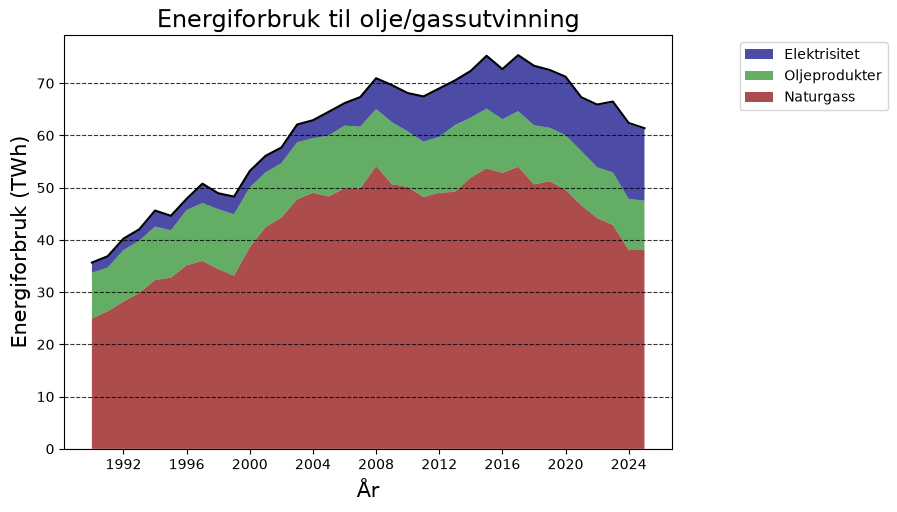

In [ ]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    oljeindustri_forbruk['år'].unique().astype(int),
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Naturgass', 'value'] / 1e3,
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Olje og oljeprodukter (ekskl. bio)', 'value'] / 1e3,
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Elektrisitet', 'value'] / 1e3,
    labels=['Naturgass', 'Oljeprodukter', 'Elektrisitet'],
    colors=['darkred', 'forestgreen', 'navy'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(oljeindustri_forbruk['år'].unique().astype(int), 
        oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Alle energiprodukter', 'value'] / 1e3, 
        color = 'black')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Energiforbruk til olje/gassutvinning', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()